# 7. Báo cáo model nhận diện ảnh (YOLO)

Server đang chạy **YOLOv8s Open Images V7** (Ultralytics huấn luyện sẵn, gộp 601 lớp về 78 nhãn của LingoPrism)
**kết hợp YOLOv10n COCO**: hai model cùng chạy, mỗi vật giữ nhãn tự tin nhất (`BE/apps/detection/inference.py`).
Model **v1 tự train** trên Colab được giữ lại để so sánh.

1. Kết quả train trên Colab (`train_yolov10_colab.ipynb`): giải nén vào `AI/runs/<tên>/` (mục 7.1–7.3).
2. **Tập test có gắn box** (mục 7.4–7.5): COCO-2017 val + Open Images V7 val, không model nào train trên đó →
   ma trận nhầm lẫn, accuracy, precision / recall / F1, mAP50, mAP50-95 của mọi cách chạy.
3. **So sánh trên ảnh thật** (mục 7.7): ảnh từ vựng đã duyệt + ảnh tự chụp trong `AI/eval_photos/`.
   Model pretrained không có tập test gắn box nên không có mAP: precision / recall đo trên ảnh thật được ghi vào
   trang admin (Nhận diện YOLO → Model) và vào `model_card.json`.
4. Mọi số liệu và ảnh cho báo cáo được lưu ở `AI/report/yolo/` (ảnh vẽ box: `detections/.../dung`, `.../sai`)
   và biểu đồ ở `AI/notebooks/figures/07_*.png`.

> **Cách chạy:** mở bằng VS Code (hoặc Jupyter), chọn kernel **LingoPrism (BE venv)** rồi *Run All*. PostgreSQL phải đang chạy. Notebook dùng đúng mã nguồn của server (`BE/apps/algorithms`), kết quả được lưu vào database nên trang **Admin → Thuật toán AI** hiện ngay kết quả mới nhất.

In [1]:
# Khởi tạo: nạp Django của BE/ (database + mã thuật toán thật của server) và matplotlib
import pathlib, sys
_here = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "AI/notebooks/lingoprism_setup.py").exists())
sys.path.insert(0, str(_here / "AI/notebooks"))
from lingoprism_setup import ROOT, init, save, table
init()

import random, time
import numpy as np
import matplotlib.pyplot as plt

Django OK – config.settings.dev | hình lưu ở D:\kicuoi\doantotnghiep\SnapLingua-main\AI\notebooks\figures


In [2]:
import json
from IPython.display import Image, display
from apps.algorithms import yolo_report

runs = [yolo_report.import_run(f) for f in sorted((ROOT / "AI" / "runs").glob("*")) if (f / "model_card.json").exists()]
table([{"model": r["name"], "epoch": r["train_args"].get("epochs"), **{k: round(r["metrics"].get(k, 0), 4)
        for k in ("precision", "recall", "map50", "map50_95")}, "TFLite": r["tflite"]} for r in runs])

model                    epoch  precision  recall  map50   map50_95  TFLite
-----------------------  -----  ---------  ------  ------  --------  ------
lingoprism-yolov10n      50     0.4247     0.3469  0.3271  0.2200    False 
lingoprism-yolov8s-ft    30     0.5190     0.4453  0.4668  0.3316    True  
yolov8s-oiv7-lingoprism  None   0.7778     0.5001  0.6327  0.4932    True  
yolov8s-oiv7-lingoprism  None   0          0       0       0         False 
yolov8m-oiv7-lingoprism  None   0.7510     0.6020  0.6963  0.5639    False 
yolov8n-oiv7-lingoprism  None   0          0       0       0         False 
yolov8s-oiv7-lingoprism  None   0.7787     0.4938  0.6238  0.4865    True  


## 7.1 Đường cong huấn luyện (model tự train)

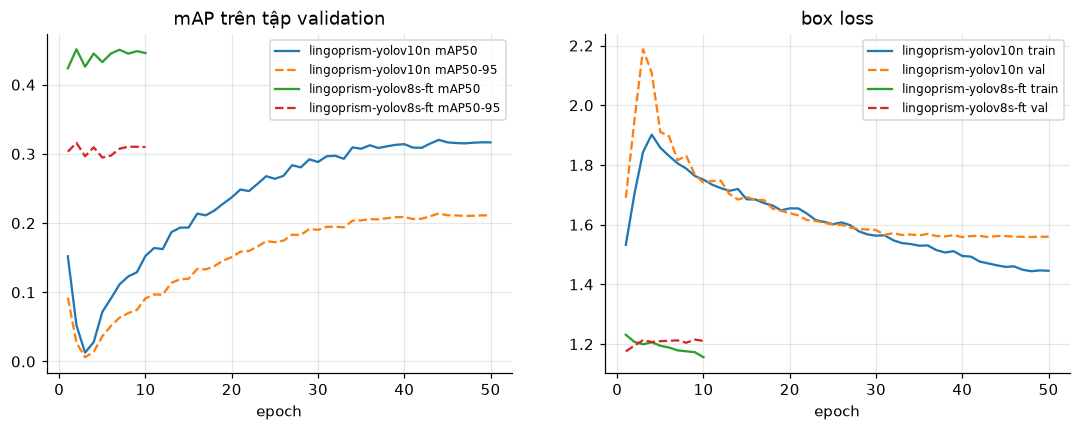

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for r in runs:
    c = r["curves"]
    if c:
        ax[0].plot(c["epoch"], c["map50"], label=f"{r['name']} mAP50")
        ax[0].plot(c["epoch"], c["map50_95"], "--", label=f"{r['name']} mAP50-95")
        ax[1].plot(c["epoch"], c["train_box_loss"], label=f"{r['name']} train")
        ax[1].plot(c["epoch"], c["val_box_loss"], "--", label=f"{r['name']} val")
ax[0].set_title("mAP trên tập validation"); ax[0].set_xlabel("epoch"); ax[0].legend(fontsize=8)
ax[1].set_title("box loss"); ax[1].set_xlabel("epoch"); ax[1].legend(fontsize=8)
save(fig, "07_yolo_duong_cong")
plt.show()

## 7.2 AP50 từng lớp trên tập test (model v1 tự train)

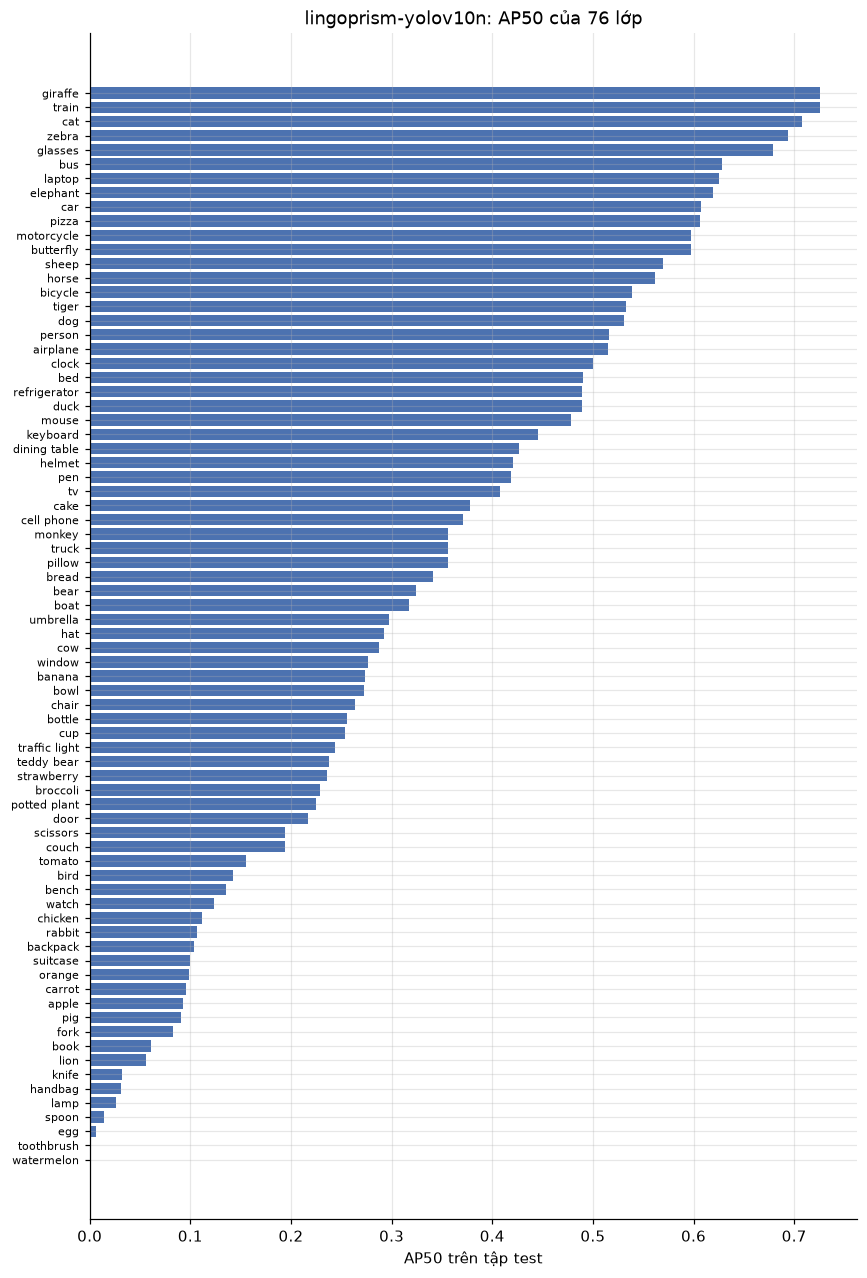

In [4]:
last = next(r for r in runs if r["curves"])  # model tự train (có đường cong train)
pc = sorted(last["per_class"], key=lambda x: -x["map50"])
fig, ax = plt.subplots(figsize=(9, 14))
ax.barh([x["label"] for x in pc][::-1], [x["map50"] for x in pc][::-1], color="#4c72b0")
ax.set_xlabel("AP50 trên tập test")
ax.set_title(f"{last['name']}: AP50 của {len(pc)} lớp")
ax.tick_params(axis="y", labelsize=7)
save(fig, "07_yolo_ap_tung_lop")
plt.show()

## 7.3 Ảnh do Ultralytics xuất khi train (confusion matrix, PR curve, ảnh dự đoán)

results.png


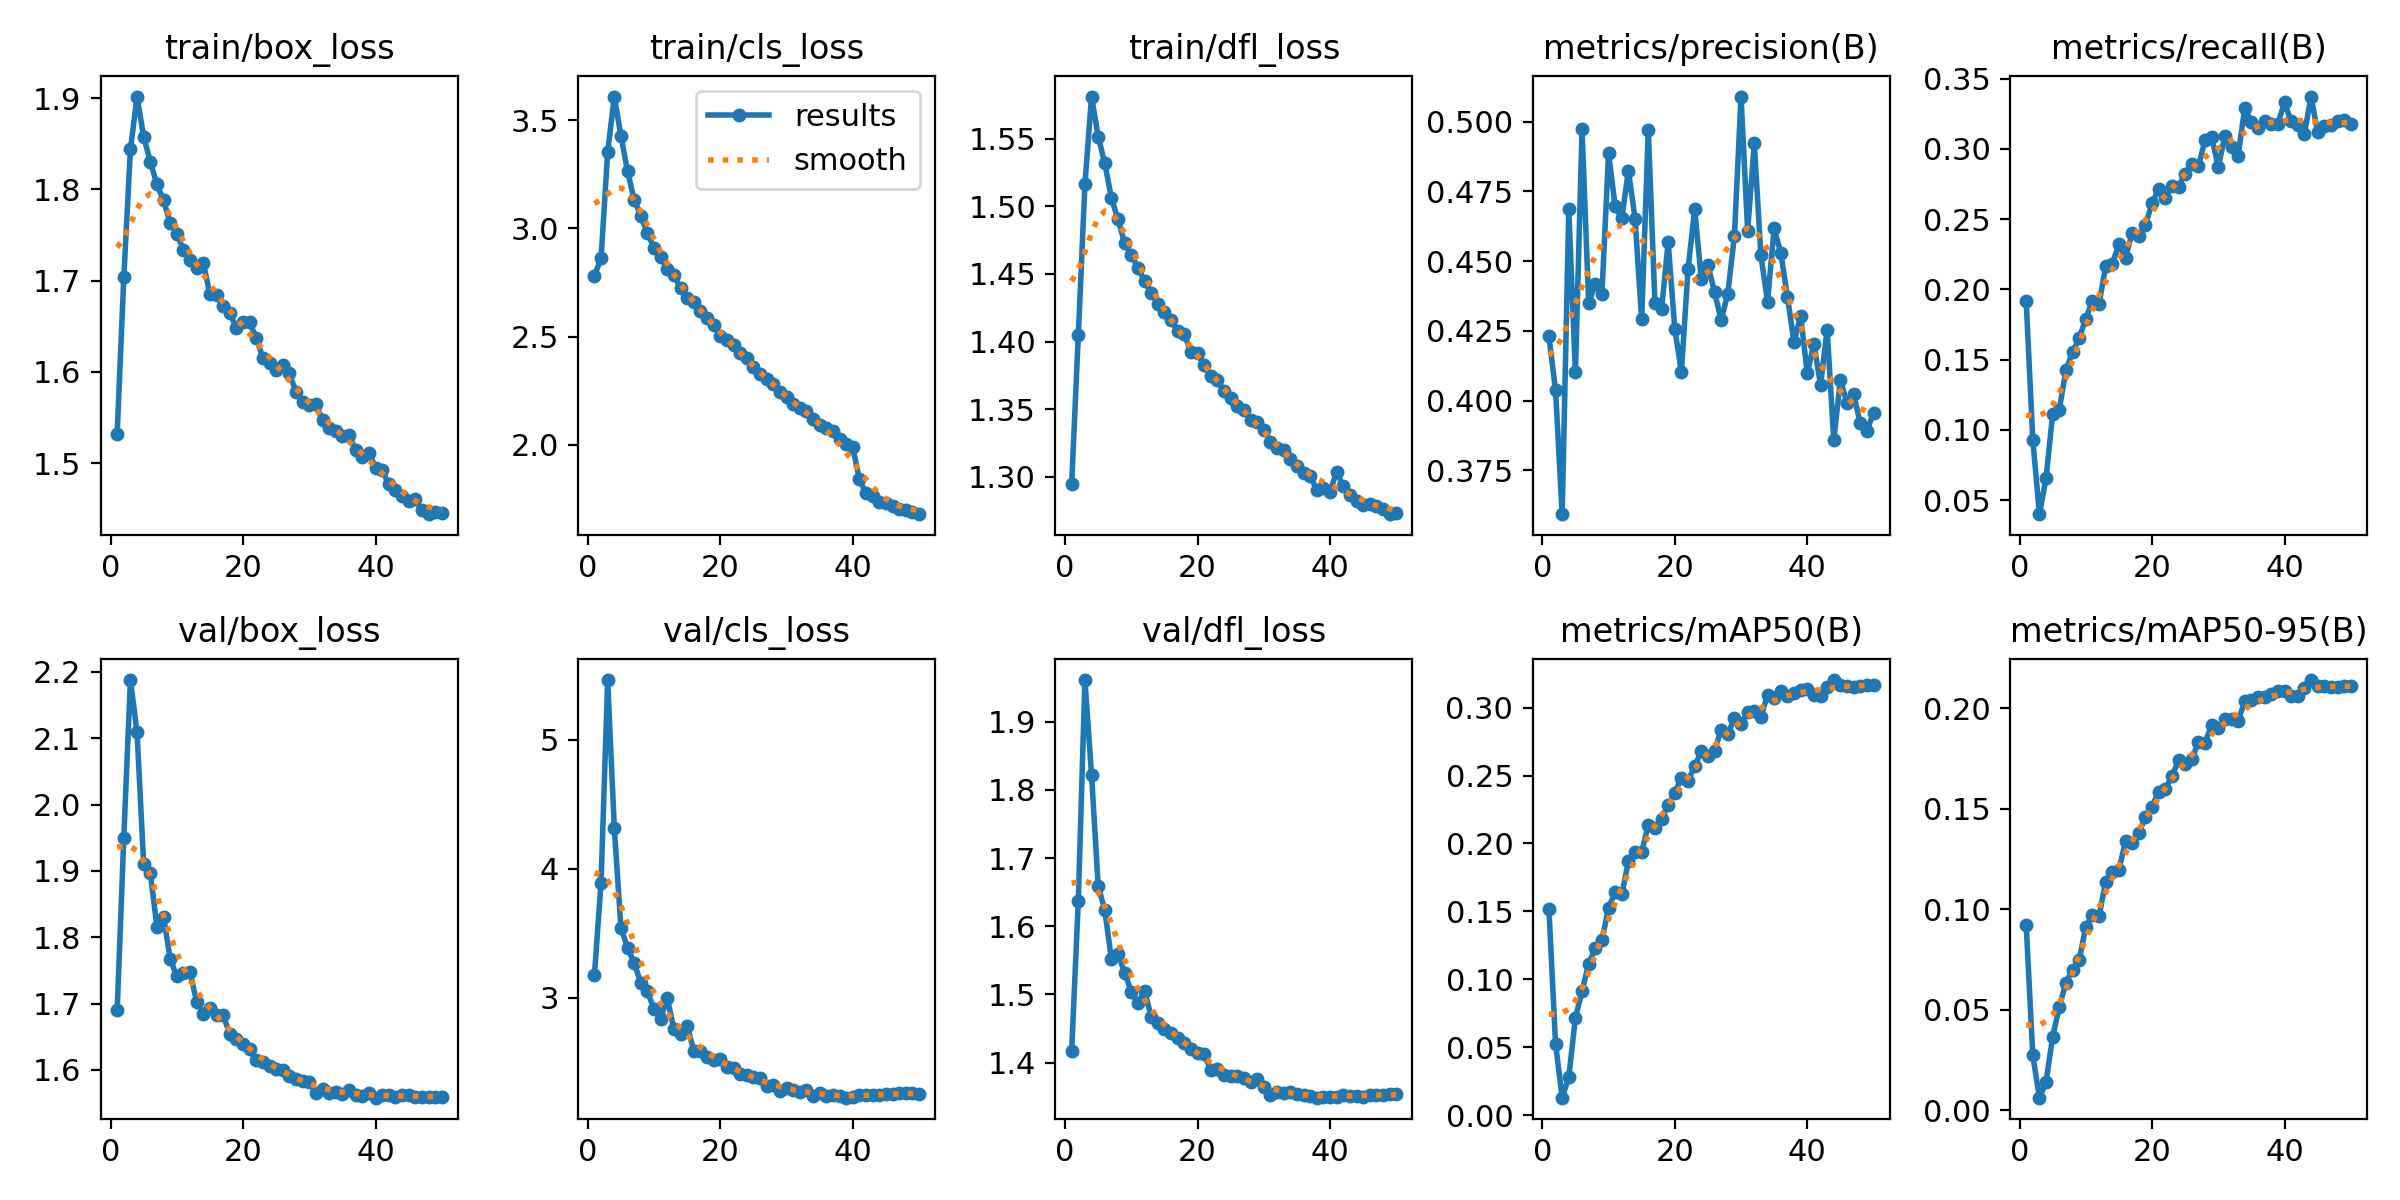

test/confusion_matrix_normalized.png


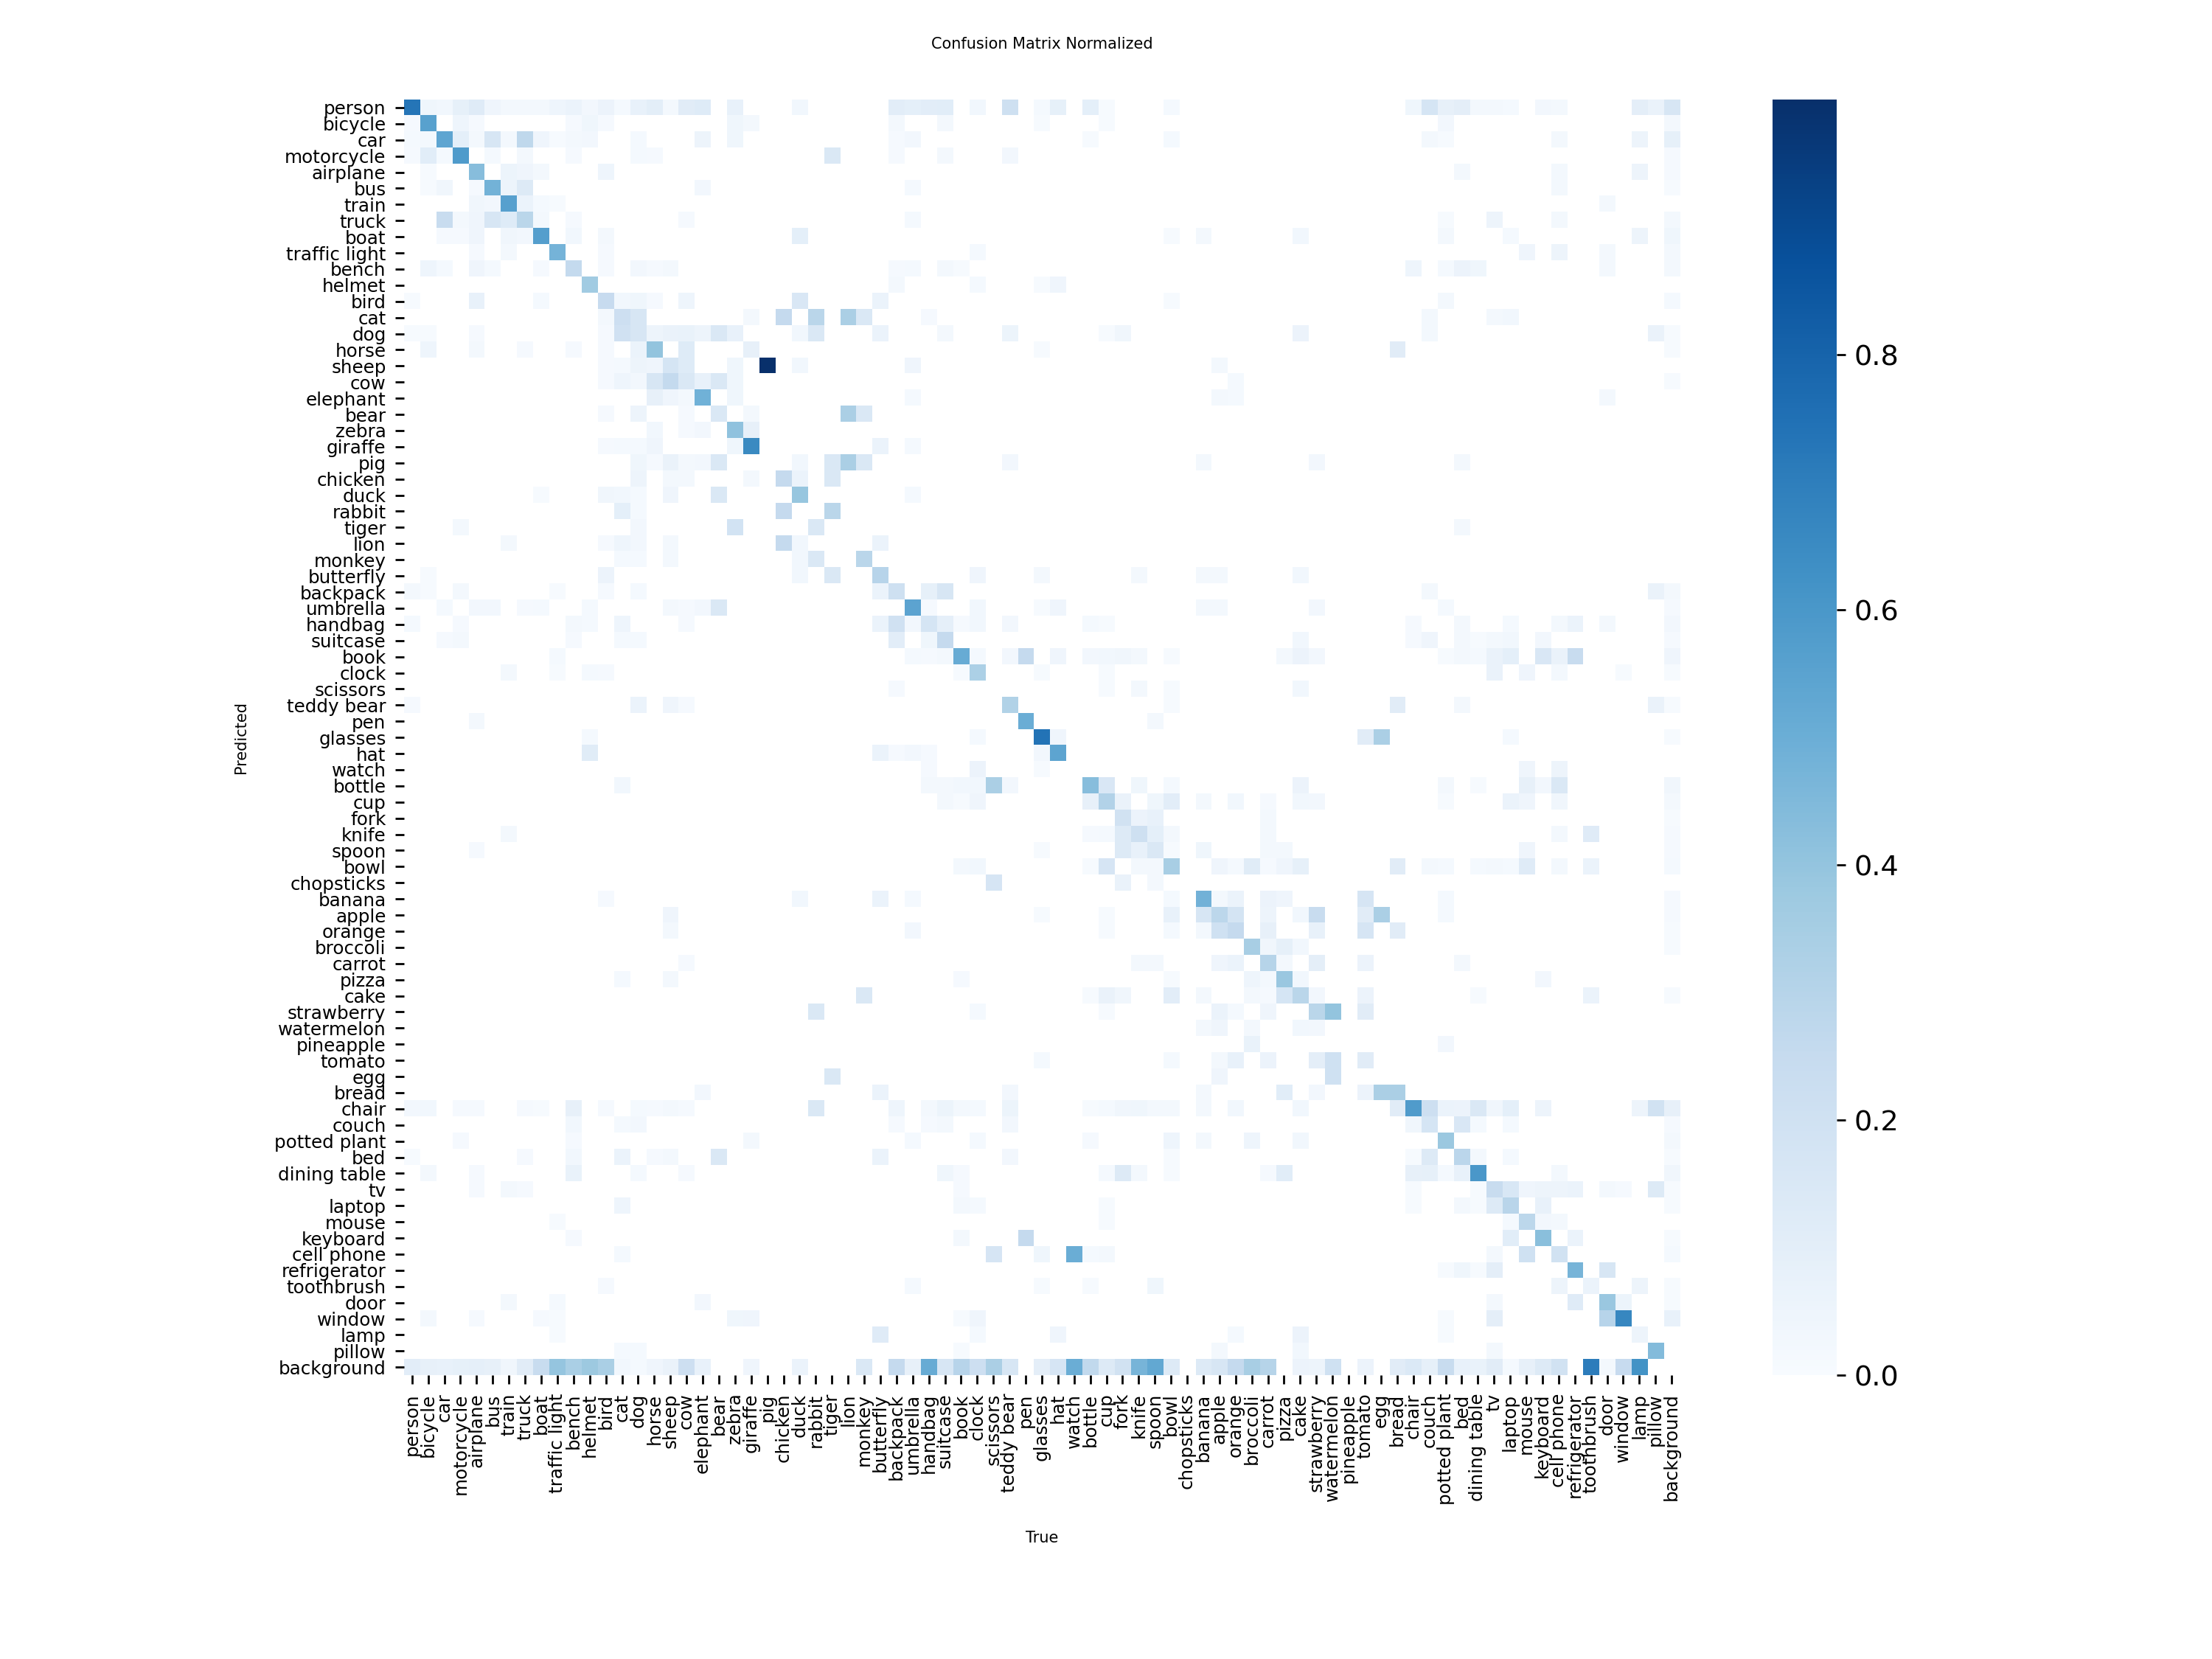

test/BoxPR_curve.png


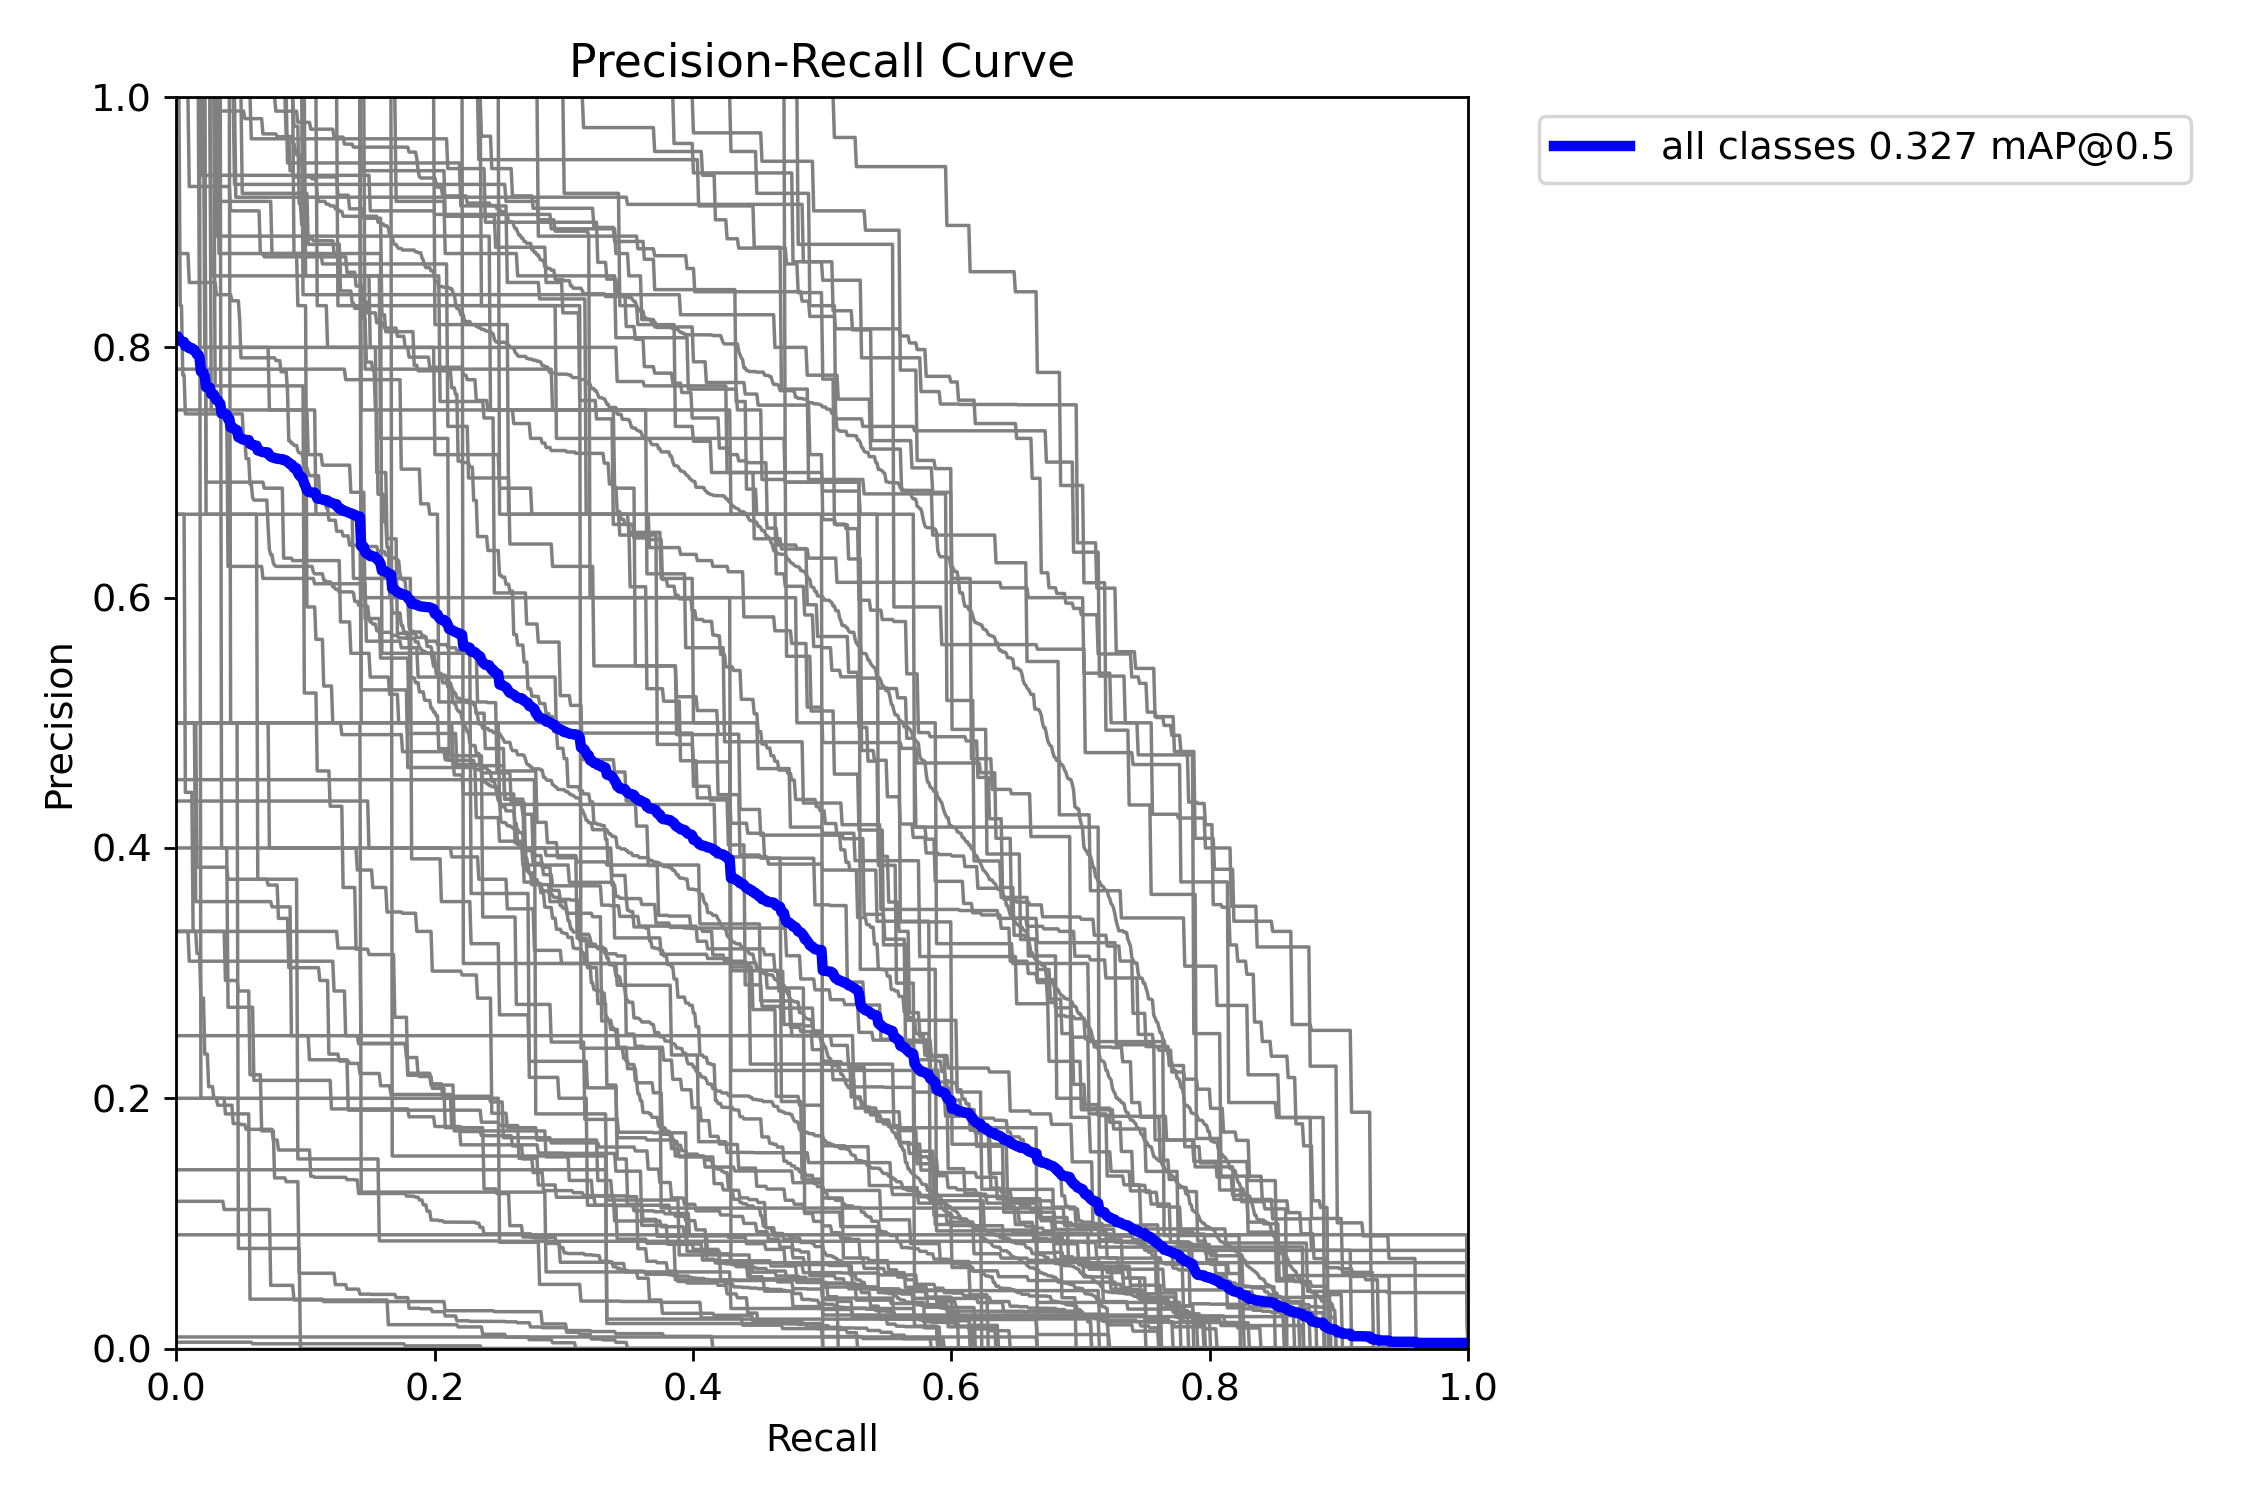

test/val_batch0_pred.jpg


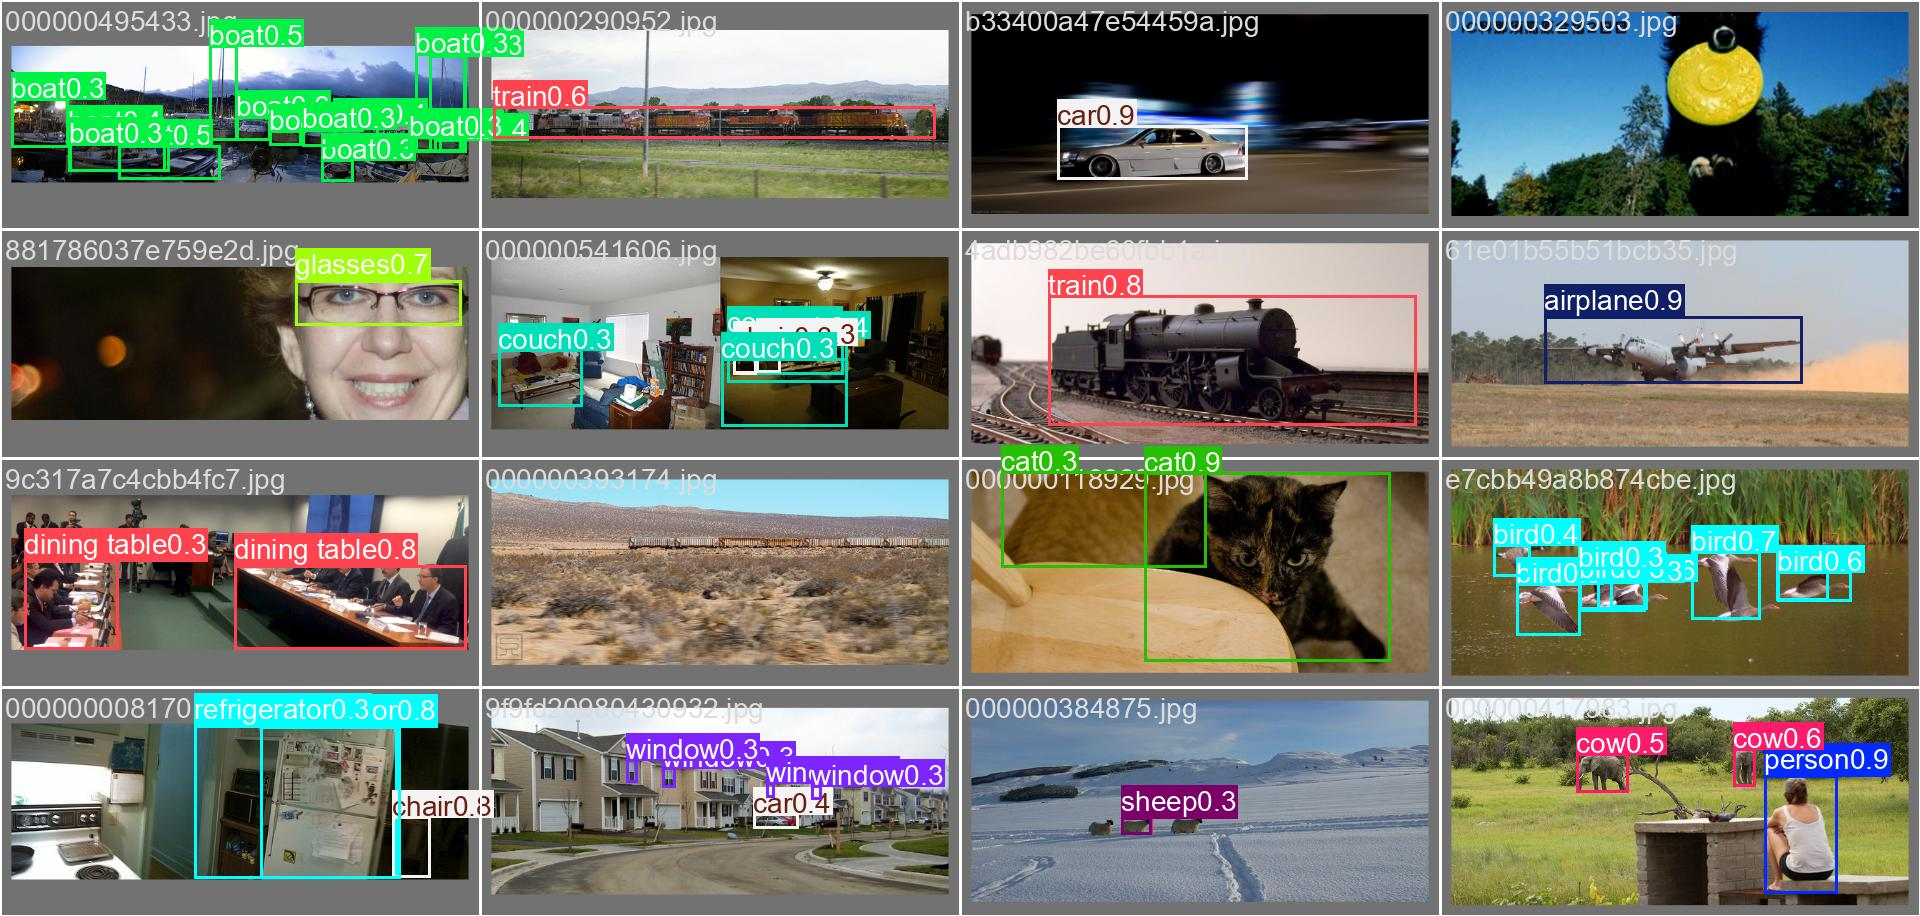

In [5]:
folder = ROOT / "AI" / "runs" / last["name"]
for rel in ["results.png", "test/confusion_matrix_normalized.png", "test/BoxPR_curve.png", "test/val_batch0_pred.jpg"]:
    if (folder / rel).exists():
        print(rel)
        display(Image(filename=str(folder / rel), width=900))

## 7.4 Tập test có gắn box: chỉ số tổng hợp

Tập test dựng bằng `AI/scripts/build_testset.py`: ảnh từ phần **validation** của COCO-2017 và Open Images V7 (mỗi lớp
tối đa 30 ảnh mỗi nguồn). Không model nào được train trên các ảnh này. Chấm bằng chính code nhận diện của server
(`AI/scripts/eval_testset.py`). Mỗi ảnh chỉ chấm các lớp mà nguồn của nó đã gắn nhãn (quy ước của Open Images),
nên một vật không được gắn nhãn không bị tính là model đoán sai.

| Chỉ số | Ý nghĩa |
|---|---|
| Precision | trong các box model đưa ra (độ tin ≥ 0,25), tỉ lệ đúng vật và đúng chỗ (IoU ≥ 0,5) |
| Recall | trong các vật thật, tỉ lệ được model tìm ra đúng |
| F1 | trung bình điều hoà của precision và recall |
| mAP50 / mAP50-95 | diện tích dưới đường precision–recall, trung bình theo lớp (IoU 0,5 / 0,5→0,95) |
| Accuracy (nhãn) | khi model đã khoanh đúng vật, tỉ lệ gọi đúng tên – "chụp 1 vật có dịch sai không" |
| Accuracy (phát hiện) | TP / (TP + FP + FN): mọi lỗi đều tính (sai nhãn, báo nhầm, bỏ sót) |

Lần chạy đầu mất khoảng 10–15 phút (dự đoán được lưu lại, các lần sau vài giây).

In [6]:
sys.path.insert(0, str(ROOT / "AI" / "scripts"))
import eval_testset as ev
test = ev.evaluate()
saved = ev.save(test)
ts = test["testset"]
print(f"\nTập test: {ts['images']} ảnh ({ts['coco']} COCO val, {ts['oi']} Open Images val), {ts['objects']} vật")
rows_t = [{"cách chạy": v["title"], "precision": v["precision"], "recall": v["recall"], "F1": v["f1"],
           "mAP50": v["map50"], "mAP50-95": v["map50_95"], "acc (nhãn)": v["accuracy_label"],
           "acc (phát hiện)": v["accuracy_detection"], "số lớp": v["classes"], "ms/ảnh": v["ms_per_image"]}
          for v in test["setups"].values()]
table(rows_t)
print("\nCOCO yolov10n chỉ được chấm trên", len(test["coco_classes"]), "lớp nó biết. So sánh công bằng theo nhóm lớp:")
table([{"cách chạy": v["title"], "mAP50 lớp COCO": v.get("on_coco_classes", v)["map50"],
        "mAP50 lớp ngoài COCO": v.get("on_other_classes", {}).get("map50", "–"),
        "F1 lớp COCO": v.get("on_coco_classes", v)["f1"], "F1 lớp ngoài COCO": v.get("on_other_classes", {}).get("f1", "–")}
       for v in test["setups"].values()])

   oiv7-78: 2542 ảnh, 0s


   coco-m: 2542 ảnh, 0s


   coco-m-int8: 2542 ảnh, 0s


   coco: 2542 ảnh, 1s


   oiv7: 2542 ảnh, 0s


...

   OIV7 yolov8m               P 0.862  R 0.386  F1 0.533  mAP50 0.639  mAP50-95 0.521  acc(nhãn) 0.963


   OIV7 m + COCO m            P 0.769  R 0.611  F1 0.681  mAP50 0.705  mAP50-95 0.574  acc(nhãn) 0.967


   OIV7 m + COCO m + CLIP     P 0.748  R 0.610  F1 0.672  mAP50 0.705  mAP50-95 0.575  acc(nhãn) 0.963


   OIV7 m + COCO m, INT8      P 0.771  R 0.603  F1 0.677  mAP50 0.698  mAP50-95 0.565  acc(nhãn) 0.967


   OIV7 m + COCO m, INT8 + CLIP (đang dùng) P 0.751  R 0.602  F1 0.668  mAP50 0.696  mAP50-95 0.564  acc(nhãn) 0.961

Tập test: 2542 ảnh (796 COCO val, 1746 Open Images val), 10016 vật
cách chạy                                 precision  recall  F1      mAP50   mAP50-95  acc (nhãn)  acc (phát hiện)  số lớp  ms/ảnh  
----------------------------------------  ---------  ------  ------  ------  --------  ----------  ---------------  ------  --------
v1 tự train                               0.6847     0.3534  0.4662  0.4530  0.3224    0.9087      0.3040           78      35.7000 
COCO yolov10n                             0.7739     0.5075  0.6130  0.6088  0.4677    0.9554      0.4419           54      44.8000 
v1 + COCO                                 0.6791     0.4730  0.5576  0.5175  0.3915    0.9411      0.3866           78      80.5000 
OIV7 s 78 lớp + COCO n (cũ)               0.7778     0.5001  0.6088  0.6327  0.4932    0.9565      0.4376           78      212.5000
OIV7 yolov8s     

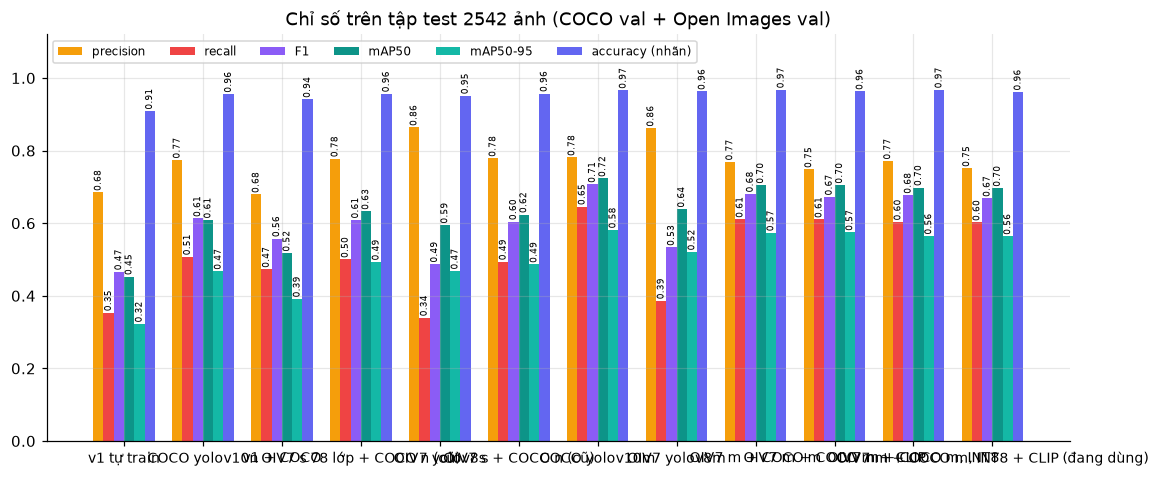

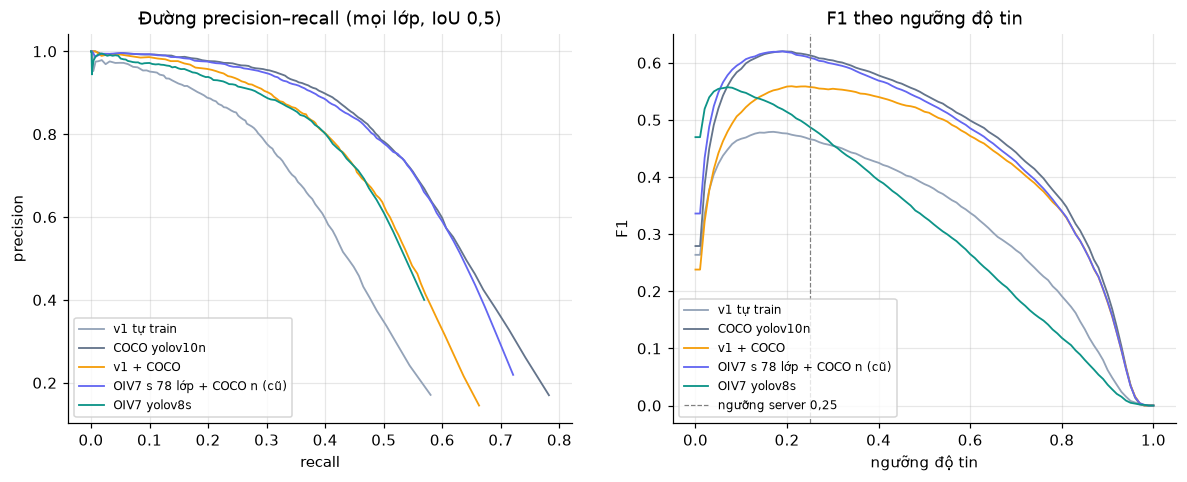

In [7]:
keys = [("precision", "precision"), ("recall", "recall"), ("F1", "F1"), ("mAP50", "mAP50"), ("mAP50-95", "mAP50-95"),
        ("acc (nhãn)", "accuracy (nhãn)")]
colors = ["#f59e0b", "#ef4444", "#8b5cf6", "#0d9488", "#14b8a6", "#6366f1"]
fig, ax = plt.subplots(figsize=(12, 4.8))
x = np.arange(len(rows_t))
wdt = 0.13
for i, ((k, name), col) in enumerate(zip(keys, colors)):
    vals = [r[k] for r in rows_t]
    bars = ax.bar(x + (i - 2.5) * wdt, vals, wdt, label=name, color=col)
    ax.bar_label(bars, labels=[f"{v:.2f}" for v in vals], fontsize=6, padding=1, rotation=90)
ax.set_xticks(x, [r["cách chạy"] for r in rows_t], fontsize=9)
ax.set_ylim(0, 1.12)
ax.set_title(f"Chỉ số trên tập test {ts['images']} ảnh (COCO val + Open Images val)")
ax.legend(ncol=6, fontsize=8, loc="upper left")
save(fig, "07_test_chi_so")
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for (k, v), col in zip(test["setups"].items(), ["#94a3b8", "#64748b", "#f59e0b", "#6366f1", "#0d9488"]):
    c = v["curve"]
    ax[0].plot([q["recall"] for q in c], [q["precision"] for q in c], label=v["title"], color=col, lw=2 if k == ev.ACTIVE else 1.2)
    ax[1].plot([q["conf"] for q in c], [q["f1"] for q in c], label=v["title"], color=col, lw=2 if k == ev.ACTIVE else 1.2)
ax[0].set_xlabel("recall"); ax[0].set_ylabel("precision"); ax[0].set_title("Đường precision–recall (mọi lớp, IoU 0,5)")
ax[1].set_xlabel("ngưỡng độ tin"); ax[1].set_ylabel("F1"); ax[1].set_title("F1 theo ngưỡng độ tin")
ax[1].axvline(ev.SERVE_CONF, ls="--", c="gray", lw=0.8, label="ngưỡng server 0,25")
ax[0].legend(fontsize=8); ax[1].legend(fontsize=8)
save(fig, "07_test_pr_f1")
plt.show()

## 7.5 Ma trận nhầm lẫn và AP từng lớp (cách server đang chạy: OIV7 + COCO)

Cột = vật thật, hàng = model trả lời, chuẩn hoá theo cột (mỗi cột cộng lại = 1). Đường chéo = gọi đúng tên;
hàng **background** = vật bị bỏ sót; cột **background** = báo một vật không có thật. Ma trận này cũng được lưu cho
VIP (notebook 3) thay cho cách đo trên ảnh từ vựng.

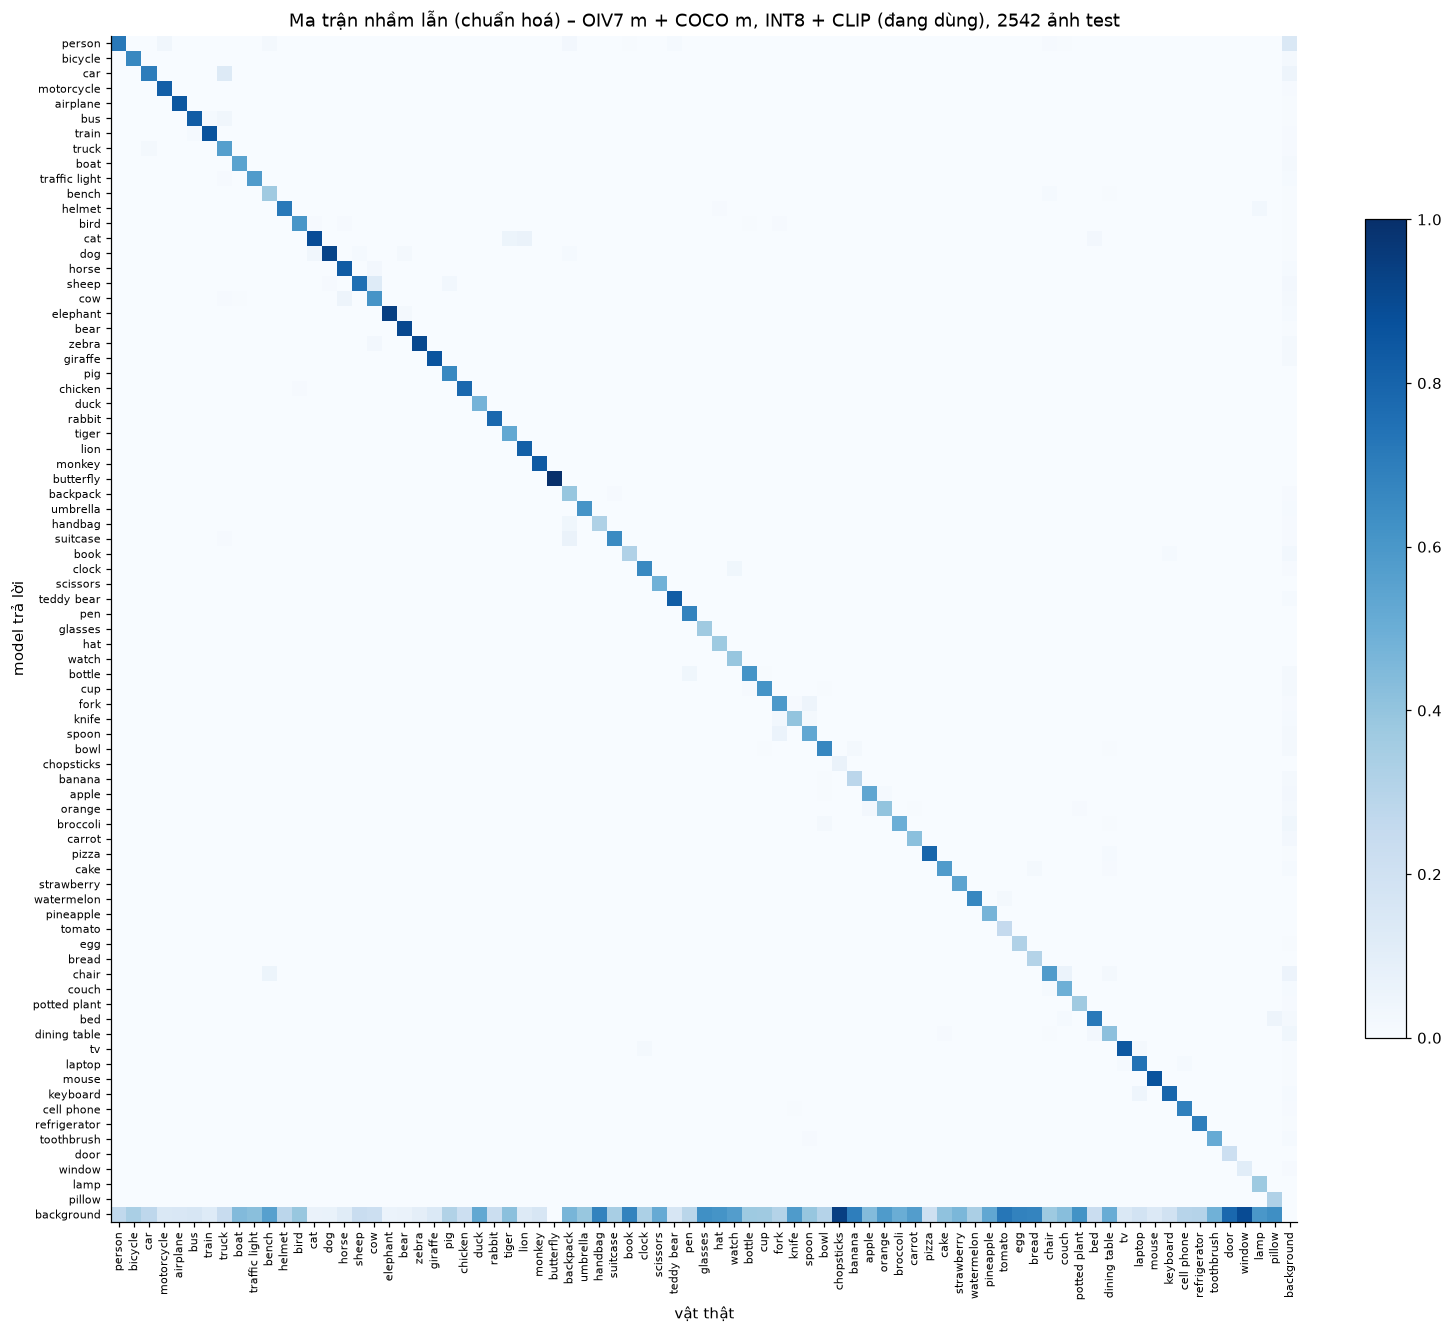

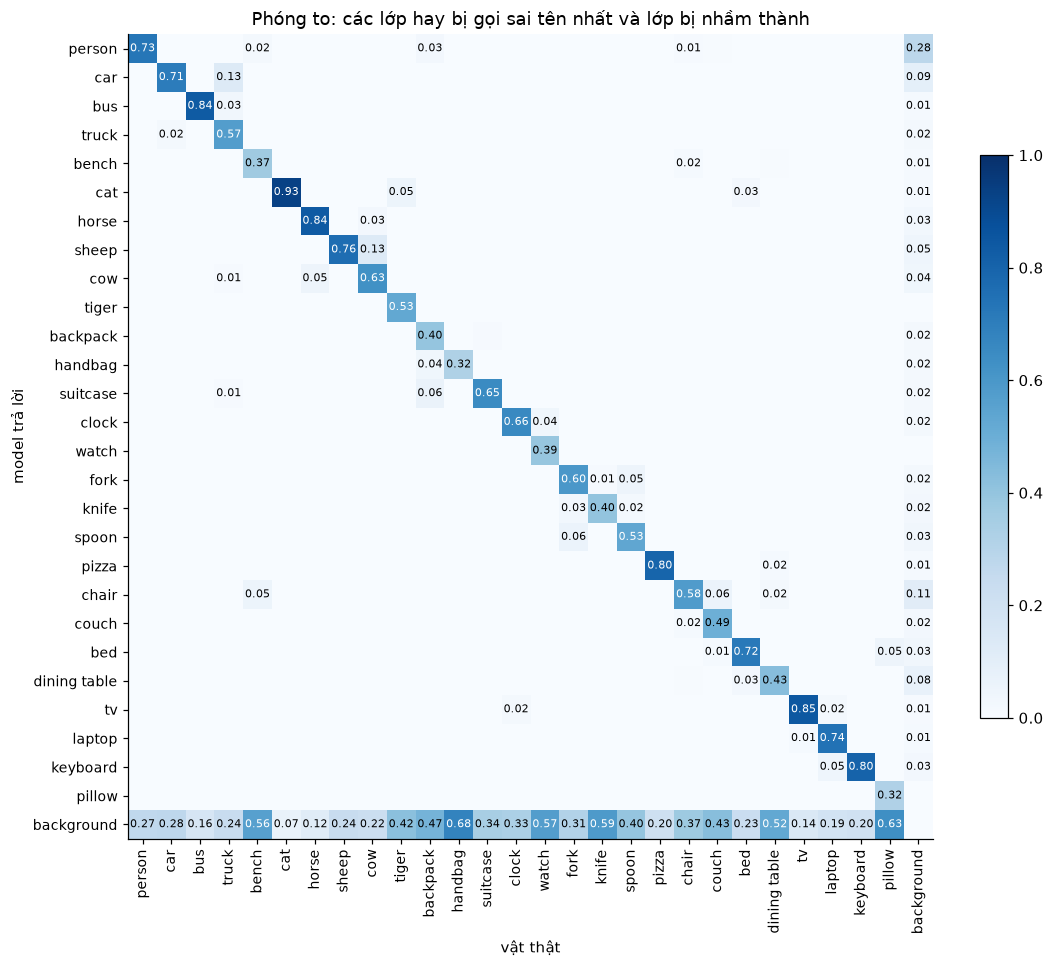

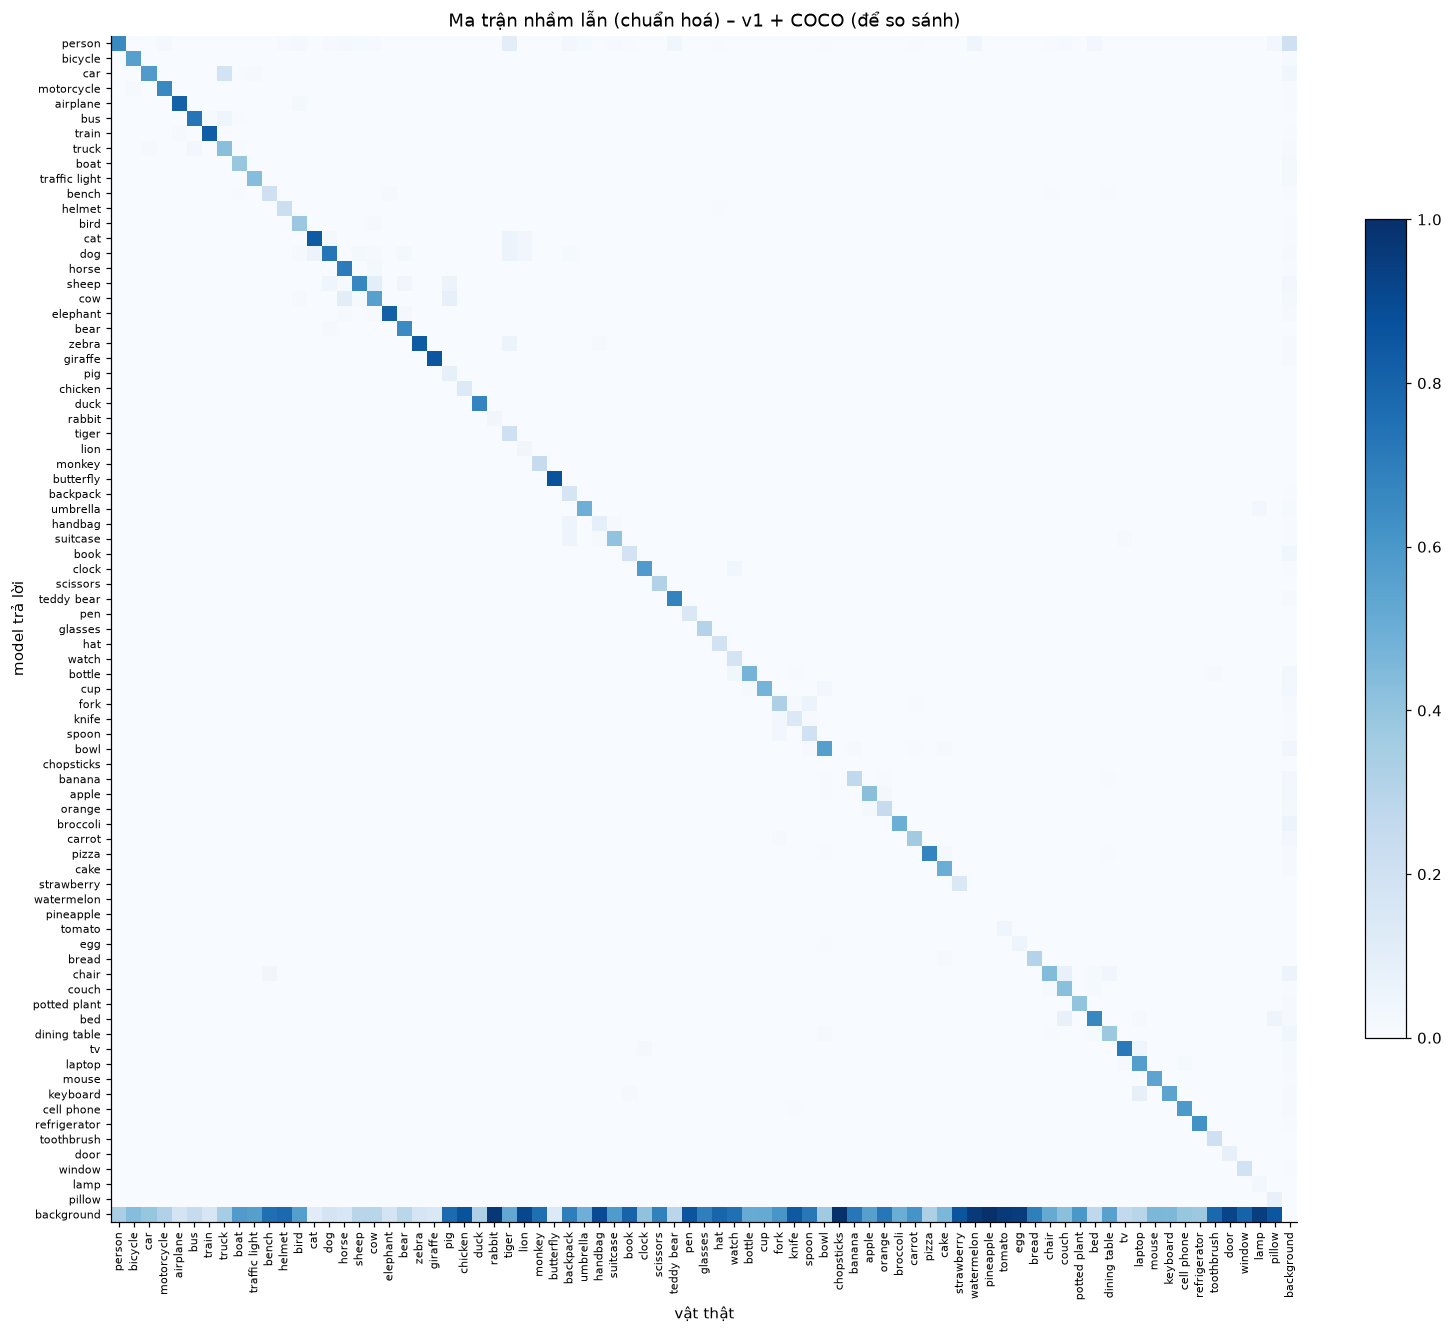

In [8]:
def plot_cm(cm_data, title, name, only=None, size=(16, 14), annotate=False):
    labels, m = cm_data["labels"], np.array(cm_data["matrix"], dtype=float)
    keep = [i for i, l in enumerate(labels) if (only is None or l in only or l == "background") and m[:, i].sum() + m[i, :].sum() > 0]
    m = m[np.ix_(keep, keep)]
    lab = [labels[i] for i in keep]
    norm = m / np.maximum(m.sum(axis=0, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=size)
    im = ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(lab)), lab, rotation=90, fontsize=7 if len(lab) > 30 else 9)
    ax.set_yticks(range(len(lab)), lab, fontsize=7 if len(lab) > 30 else 9)
    ax.set_xlabel("vật thật"); ax.set_ylabel("model trả lời"); ax.grid(False)
    if annotate:
        for i in range(len(lab)):
            for j in range(len(lab)):
                if norm[i, j] >= 0.01:
                    ax.text(j, i, f"{norm[i, j]:.2f}", ha="center", va="center", fontsize=7,
                            color="white" if norm[i, j] > 0.5 else "black")
    ax.set_title(title)
    fig.colorbar(im, ax=ax, fraction=0.03)
    save(fig, name)
    plt.show()

act = test["setups"][ev.ACTIVE]
plot_cm(act["confusion_matrix"], f"Ma trận nhầm lẫn (chuẩn hoá) – {act['title']}, {ts['images']} ảnh test", "07_test_ma_tran_nham_lan")

# the classes most often given a wrong name: readable close-up with the numbers
lab, m = act["confusion_matrix"]["labels"], np.array(act["confusion_matrix"]["matrix"])
bgi = len(lab) - 1
wrong = {lab[j]: (m[:bgi, j].sum() - m[j, j]) / max(m[:bgi, j].sum(), 1) for j in range(bgi) if m[:bgi, j].sum() >= 5}
top = sorted(wrong, key=lambda c: -wrong[c])[:12]
partners = {lab[i] for j in (lab.index(c) for c in top) for i in np.argsort(-m[:bgi, j])[:3] if m[i, j] > 0}
plot_cm(act["confusion_matrix"], "Phóng to: các lớp hay bị gọi sai tên nhất và lớp bị nhầm thành", "07_test_ma_tran_nham_lan_top",
        only=set(top) | partners, size=(11, 9.5), annotate=True)

v1 = test["setups"].get("v1+coco")
if v1:
    plot_cm(v1["confusion_matrix"], f"Ma trận nhầm lẫn (chuẩn hoá) – {v1['title']} (để so sánh)", "07_test_ma_tran_nham_lan_v1")

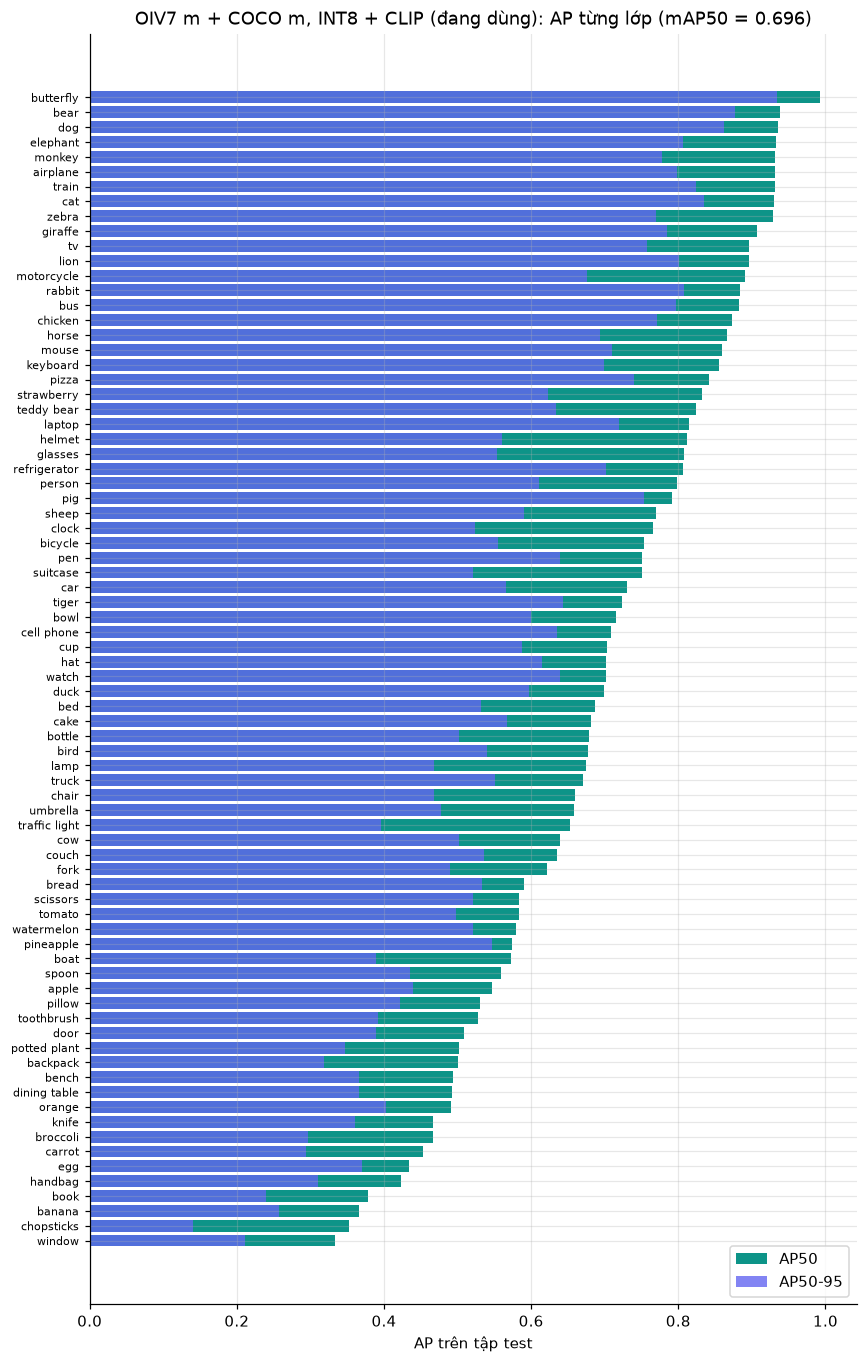

lớp           số vật  precision  recall  F1      AP50  
------------  ------  ---------  ------  ------  ------
bench         57      0.5714     0.4211  0.4848  0.4936
dining table  274     0.6096     0.4161  0.4946  0.4923
orange        135     0.5833     0.4148  0.4848  0.4909
knife         175     0.7083     0.3886  0.5018  0.4672
broccoli      165     0.5168     0.4667  0.4904  0.4672
carrot        133     0.5773     0.4211  0.4870  0.4535
egg           63      0.6786     0.3016  0.4176  0.4340
handbag       112     0.6000     0.3214  0.4186  0.4232
book          216     0.5630     0.3102  0.4000  0.3788
banana        106     0.4247     0.2925  0.3464  0.3663
chopsticks    16      0.3333     0.0625  0.1053  0.3520
window        361     0.6491     0.1025  0.1770  0.3335
(12 lớp yếu nhất – ứng viên ưu tiên khi train v3)
Trang admin: {'precision': 0.751, 'recall': 0.602, 'map50': 0.6963, 'map50_95': 0.5639}


In [9]:
pc = sorted(act["per_class"].items(), key=lambda kv: -kv[1]["map50"])
fig, ax = plt.subplots(figsize=(9, 15))
ax.barh([k for k, _ in pc][::-1], [v["map50"] for _, v in pc][::-1], color="#0d9488", label="AP50")
ax.barh([k for k, _ in pc][::-1], [v["map50_95"] for _, v in pc][::-1], color="#6366f1", alpha=0.8, label="AP50-95")
ax.set_xlabel("AP trên tập test")
ax.set_title(f"{act['title']}: AP từng lớp (mAP50 = {act['map50']:.3f})")
ax.tick_params(axis="y", labelsize=7)
ax.legend(loc="lower right")
save(fig, "07_test_ap_tung_lop")
plt.show()

table([{"lớp": k, "số vật": v["n_gt"], "precision": v["precision"], "recall": v["recall"], "F1": v["f1"], "AP50": v["map50"]}
       for k, v in pc[-12:]])
print("(12 lớp yếu nhất – ứng viên ưu tiên khi train v3)")

# admin: the active model now has real test-set metrics (mAP), replacing the photo-based estimate
from apps.detection.models import ModelVersion
card = json.loads((ROOT / "AI/runs/oiv7-pretrained/model_card.json").read_text(encoding="utf-8"))
ModelVersion.objects.filter(name=card["name"]).update(**card["metrics"], notes=card["metrics_note"])
print("Trang admin:", card["metrics"])

## 7.6 Đăng ký model mới vào server (chạy một lần cho mỗi model)
Bỏ dấu `#` ở dòng dưới và sửa tên nếu là model mới. Sau đó chạy lại **notebook 3 (VIP)** để dùng confusion matrix mới.

In [10]:
# NAME = "lingoprism-yolov10n-v2"
# !"{sys.executable}" manage.py register_model --onnx models/{NAME}.onnx --card ../AI/runs/{NAME}/model_card.json

## 7.7 So sánh trên ảnh thật: model riêng lẻ / COCO gốc / kết hợp

* **Ảnh từ vựng**: mỗi từ có nhãn YOLO một ảnh thật đã duyệt (Wikimedia Commons), không nằm trong dữ liệu train.
* **Ảnh tự chụp**: mọi ảnh trong `AI/eval_photos/`, tên file là vật trong ảnh: `cup.jpg`, `cup_2.jpg`,
  `cup+spoon+bowl.jpg` (nhiều vật), hoặc thư mục `pillow/IMG_001.jpg`.

Chỉ số: **top-1** = box tự tin nhất là đúng vật; **tìm thấy** (recall) = tỉ lệ vật có trong ảnh được nhận ra;
**precision** = box có nhãn đúng / mọi box (vật thật khác ở nền bị tính là sai nên đây là cận dưới).
COCO gốc chỉ được hỏi các lớp nó biết. Chạy trên CPU khoảng 1 phút.

In [11]:
REPORT = ROOT / "AI" / "report" / "yolo"
run = yolo_report.run()
comp = run.results["comparison"]
KIND = {"trained": "riêng lẻ", "coco": "COCO gốc", "combined": "kết hợp với COCO"}
rows = []
for m in comp["models"]:
    for set_name, res in (("ảnh từ vựng", m["results"]), ("ảnh tự chụp", m["own_photos"])):
        for k, v in res.items():
            if k == "coco" and rows and any(r["cách chạy"] == "COCO gốc" and r["bộ ảnh"] == set_name for r in rows):
                continue  # COCO alone is the same for every model
            rows.append({"bộ ảnh": set_name, "cách chạy": "COCO gốc" if k == "coco" else f"{m['model']} {KIND[k]}",
                         "đang dùng": "✓" if m["active"] and k == "combined" else "", "số ảnh": v["photos"],
                         "top-1": v["top1"], "tìm thấy": v["found"], "precision": v["precision"],
                         "box sai": v["wrong_boxes"], "top-1 lớp ngoài COCO": v["top1_new_classes"], "ms/ảnh": v["ms_per_image"]})
table(rows)
own = sum(m["own_photos"].get("combined", {}).get("photos", 0) for m in comp["models"] if m["active"])
print(f"\nẢnh tự chụp trong AI/eval_photos/: {own}" + ("  (chưa có – chụp thêm để đánh giá sát thực tế)" if not own else ""))
print("\nGhi vào trang admin (model đang dùng):", run.results["applied_metrics"])

bộ ảnh       cách chạy                                 đang dùng  số ảnh  top-1   tìm thấy  precision  box sai  top-1 lớp ngoài COCO  ms/ảnh  
-----------  ----------------------------------------  ---------  ------  ------  --------  ---------  -------  --------------------  --------
ảnh từ vựng  lingoprism-yolov10n riêng lẻ                         78      0.5000  0.5385    0.5468     63       0.3333                39.8000 
ảnh từ vựng  COCO gốc                                             54      0.8704  0.9444    0.6467     53       None                  126.2000
ảnh từ vựng  lingoprism-yolov10n kết hợp với COCO                 78      0.8077  0.9103    0.6636     72       0.6667                230.5000
ảnh từ vựng  yolov8s-oiv7-lingoprism riêng lẻ                     231     0.6190  0.6710    0.6231     150      0.5962                160.9000
ảnh từ vựng  yolov8s-oiv7-lingoprism kết hợp với COCO             231     0.7662  0.8485    0.6346     209      0.7051                338.5000

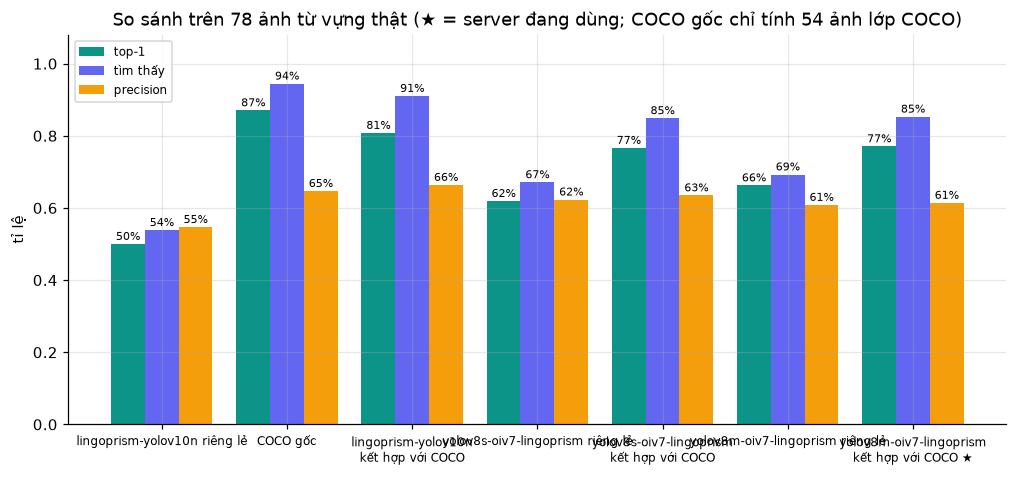

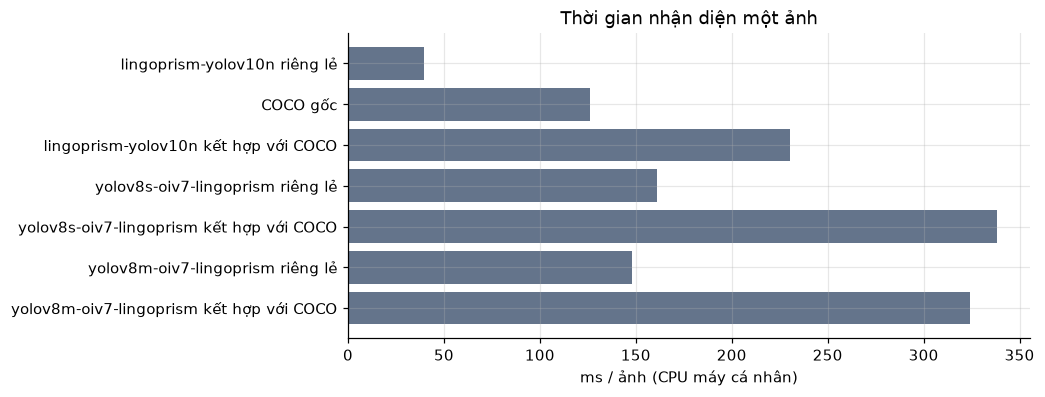

In [12]:
word_rows = [r for r in rows if r["bộ ảnh"] == "ảnh từ vựng"]
fig, ax = plt.subplots(figsize=(11, 4.6))
x = np.arange(len(word_rows))
for i, (key, color) in enumerate((("top-1", "#0d9488"), ("tìm thấy", "#6366f1"), ("precision", "#f59e0b"))):
    vals = [r[key] or 0 for r in word_rows]
    bars = ax.bar(x + (i - 1) * 0.27, vals, 0.27, label=key, color=color)
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in vals], fontsize=7, padding=1)
ax.set_xticks(x, [r["cách chạy"].replace(" kết hợp", "\nkết hợp") + (" ★" if r["đang dùng"] else "") for r in word_rows], fontsize=8)
ax.set_ylim(0, 1.08)
ax.set_ylabel("tỉ lệ")
ax.set_title(f"So sánh trên {word_rows[0]['số ảnh']} ảnh từ vựng thật (★ = server đang dùng; COCO gốc chỉ tính {next(r['số ảnh'] for r in word_rows if r['cách chạy'] == 'COCO gốc')} ảnh lớp COCO)")
ax.legend(loc="upper left", fontsize=8)
save(fig, "07_so_sanh_model_anh_that")
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh([r["cách chạy"] for r in word_rows][::-1], [r["ms/ảnh"] for r in word_rows][::-1], color="#64748b")
ax.set_xlabel("ms / ảnh (CPU máy cá nhân)")
ax.set_title("Thời gian nhận diện một ảnh")
save(fig, "07_toc_do")
plt.show()

## 7.8 Kết quả từng lớp và các lỗi của cách server đang chạy
Xanh = box tự tin nhất đúng vật, đỏ = sai. Danh sách lỗi cho biết model hay nhầm thành gì, dùng làm đầu vào cho VIP (notebook 3)
và để quyết định có cần train thêm lớp nào không.

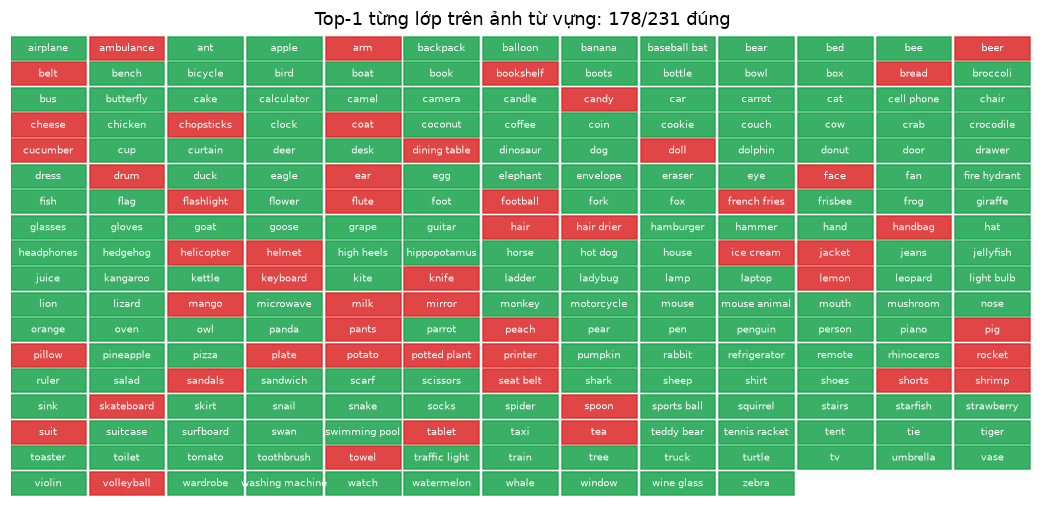

đáp án        model trả lời    độ tin  có trong kết quả
------------  ---------------  ------  ----------------
ambulance     person           0.8080  ✗               
arm           person           0.9212  ✗               
beer          wine glass       0.9533  ✗               
belt          (không thấy gì)          ✗               
bookshelf     person           0.4094  ✓               
bread         donut            0.9756  ✓               
candy         (không thấy gì)          ✗               
cheese        orange           0.6755  ✓               
chopsticks    pen              0.5465  ✓               
coat          face             0.7499  ✓               
cucumber      flower           0.6837  ✗               
dining table  vase             0.9107  ✓               
doll          face             0.5000  ✓               
drum          suitcase         0.6362  ✗               
ear           face             0.6364  ✗               
face          person           0.9481  ✓        

In [13]:
per = comp["active_per_photo"].get("word_photos", [])
per = sorted(per, key=lambda r: r["expected"][0])
fig, ax = plt.subplots(figsize=(12, 5.5))
cols = 13
for i, r in enumerate(per):
    cx, cy = i % cols, i // cols
    ok = r["top1_ok"]
    ax.add_patch(plt.Rectangle((cx, -cy), 0.95, 0.9, color="#16a34a" if ok else "#dc2626", alpha=0.85))
    ax.text(cx + 0.47, -cy + 0.45, r["expected"][0], ha="center", va="center", fontsize=6.5, color="white")
ax.set_xlim(0, cols)
ax.set_ylim(-(len(per) // cols) - 0.2, 1)
ax.axis("off")
ax.set_title(f"Top-1 từng lớp trên ảnh từ vựng: {sum(r['top1_ok'] for r in per)}/{len(per)} đúng")
save(fig, "07_dung_sai_tung_lop")
plt.show()

errors = [{"đáp án": r["expected"][0], "model trả lời": r["boxes"][0]["label"] if r["boxes"] else "(không thấy gì)",
           "độ tin": r["boxes"][0]["confidence"] if r["boxes"] else "",
           "có trong kết quả": "✓" if any(b["label"] in r["expected"] for b in r["boxes"]) else "✗"}
          for r in per if not r["top1_ok"]]
table(errors)

## 7.9 Lưu số liệu và ảnh cho báo cáo

In [14]:
folder = yolo_report.save_report(run, REPORT)
# precision / recall đo được cũng vào model_card.json -> server nhận khi deploy (register_model)
active = next(m for m in comp["models"] if m["active"])
applied = run.results["applied_metrics"]
card_path = next((f / "model_card.json" for f in (ROOT / "AI" / "runs").glob("*")
                  if (f / "model_card.json").exists() and json.loads((f / "model_card.json").read_text(encoding="utf-8"))["name"] == active["model"]), None)
if applied and card_path:
    card = json.loads(card_path.read_text(encoding="utf-8"))
    card["metrics"] = {"precision": applied["precision"], "recall": applied["recall"]}
    card["metrics_note"] = applied["notes"]
    card_path.write_text(json.dumps(card, ensure_ascii=False, indent=1), encoding="utf-8")
    print("Đã ghi chỉ số vào", card_path.relative_to(ROOT))

summary = ["# Nhận diện ảnh – số liệu cho báo cáo", "", f"Ngày đo: {time.strftime('%d/%m/%Y')}. {comp['note']}", "",
           "## Ảnh thật (ảnh từ vựng / ảnh tự chụp)", "", "| Bộ ảnh | Cách chạy | Số ảnh | Top-1 | Tìm thấy | Precision | Box sai | ms/ảnh |", "|---|---|---|---|---|---|---|---|"]
pct = lambda v: "–" if v is None else f"{v:.0%}"
for r in rows:
    summary.append(f"| {r['bộ ảnh']} | {r['cách chạy']}{' **(đang dùng)**' if r['đang dùng'] else ''} | {r['số ảnh']} | {pct(r['top-1'])} | "
                   f"{pct(r['tìm thấy'])} | {pct(r['precision'])} | {r['box sai']} | {r['ms/ảnh']} |")
summary += ["", f"## Tập test có gắn box ({ts['images']} ảnh: {ts['coco']} COCO-2017 val, {ts['oi']} Open Images V7 val, {ts['objects']} vật)", "",
            "| Cách chạy | Precision | Recall | F1 | mAP50 | mAP50-95 | Accuracy (nhãn) | Accuracy (phát hiện) | ms/ảnh |",
            "|---|---|---|---|---|---|---|---|---|"]
summary += [f"| {r['cách chạy']} | {r['precision']:.3f} | {r['recall']:.3f} | {r['F1']:.3f} | {r['mAP50']:.3f} | "
            f"{r['mAP50-95']:.3f} | {r['acc (nhãn)']:.3f} | {r['acc (phát hiện)']:.3f} | {r['ms/ảnh']} |" for r in rows_t]
summary += ["", "Số liệu từng lớp và ma trận nhầm lẫn: `testset/metrics.json`, `testset/confusion_matrix_*.json`. "
            "Biểu đồ: `07_test_chi_so.png`, `07_test_pr_f1.png`, `07_test_ma_tran_nham_lan.png`, `07_test_ma_tran_nham_lan_top.png`, "
            "`07_test_ma_tran_nham_lan_v1.png`, `07_test_ap_tung_lop.png`."]
summary += ["", "## Ảnh từ vựng: các ảnh model đang dùng trả lời sai (top-1)", "", "| Đáp án | Model trả lời | Độ tin | Có trong kết quả |", "|---|---|---|---|"]
summary += [f"| {e['đáp án']} | {e['model trả lời']} | {e['độ tin']} | {e['có trong kết quả']} |" for e in errors]
summary += ["", "Ảnh có vẽ box: `detections/word_photos/dung`, `detections/word_photos/sai` (xanh = đúng nhãn, đỏ = sai).",
            "Biểu đồ: `AI/notebooks/figures/07_so_sanh_model_anh_that.png`, `07_dung_sai_tung_lop.png`, `07_toc_do.png`."]
notes = folder / "ghi_chu.md"  # hand-written history of model changes, kept across re-runs
if notes.exists():
    summary += ["", notes.read_text(encoding="utf-8").rstrip()]
(folder / "README.md").write_text("\n".join(summary) + "\n", encoding="utf-8")
print("Đã lưu:", folder.relative_to(ROOT), "–", sum(1 for _ in folder.rglob("*.jpg")), "ảnh")

Đã lưu: AI\report\yolo – 231 ảnh
